# Dimensionality Reduction & Unsupervised Clustering
### Discovering structure in 30-dimensional breast-cancer cell measurements with PCA, K-Means, Hierarchical clustering and DBSCAN

**Dataset:** Wisconsin Diagnostic Breast Cancer (569 samples x 30 numeric features computed from fine-needle-aspirate images; built into scikit-learn).
**Key idea:** the diagnosis labels (malignant/benign) are **never used for fitting**. They are held back and used only at the end to check whether the clusters found without supervision mean something.

| Task requirement | Where |
|---|---|
| Standardise features + PCA | Sections 2-3 |
| Explained-variance scree plot, optimal number of components | Section 3 (4 independent criteria) |
| K-Means with Elbow + Silhouette to choose k | Section 4 (plus Gap statistic, Calinski-Harabasz, Davies-Bouldin) |
| Hierarchical and DBSCAN clustering | Sections 5 and 6 |
| 2D/3D cluster projections (Seaborn / Plotly) | Section 7 |
| Silhouette scores and comparison of methods | Sections 4 and 8 |

## 0. Setup

In [61]:
import warnings; warnings.filterwarnings("ignore")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.io as pio
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_score)
from IPython.display import display, Markdown
import sklearn, plotly, scipy

SEED = 42; rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pio.renderers.default = "notebook_connected"
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| plotly", plotly.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | plotly 7.1.0


## 1. Data

In [62]:
bc = load_breast_cancer(as_frame=True)
X_raw = bc.data.copy()                                   # features only
y_true = bc.target.map({0: "Malignant", 1: "Benign"})    # HELD OUT: validation only
print(f"{X_raw.shape[0]} samples x {X_raw.shape[1]} features | missing values: {int(X_raw.isna().sum().sum())}")
print("Held-out label balance:", y_true.value_counts().to_dict())
display(X_raw.iloc[:, :8].describe().T[["mean", "std", "min", "max"]].round(3))

569 samples x 30 features | missing values: 0
Held-out label balance: {'Benign': 357, 'Malignant': 212}


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201


## 2. Standardisation
Features live on wildly different scales (area is in the thousands, smoothness below 0.2). PCA and K-Means are distance/variance based, so without standardisation the largest-scale feature (`area`) would dominate. Each feature is rescaled to mean 0 and SD 1.

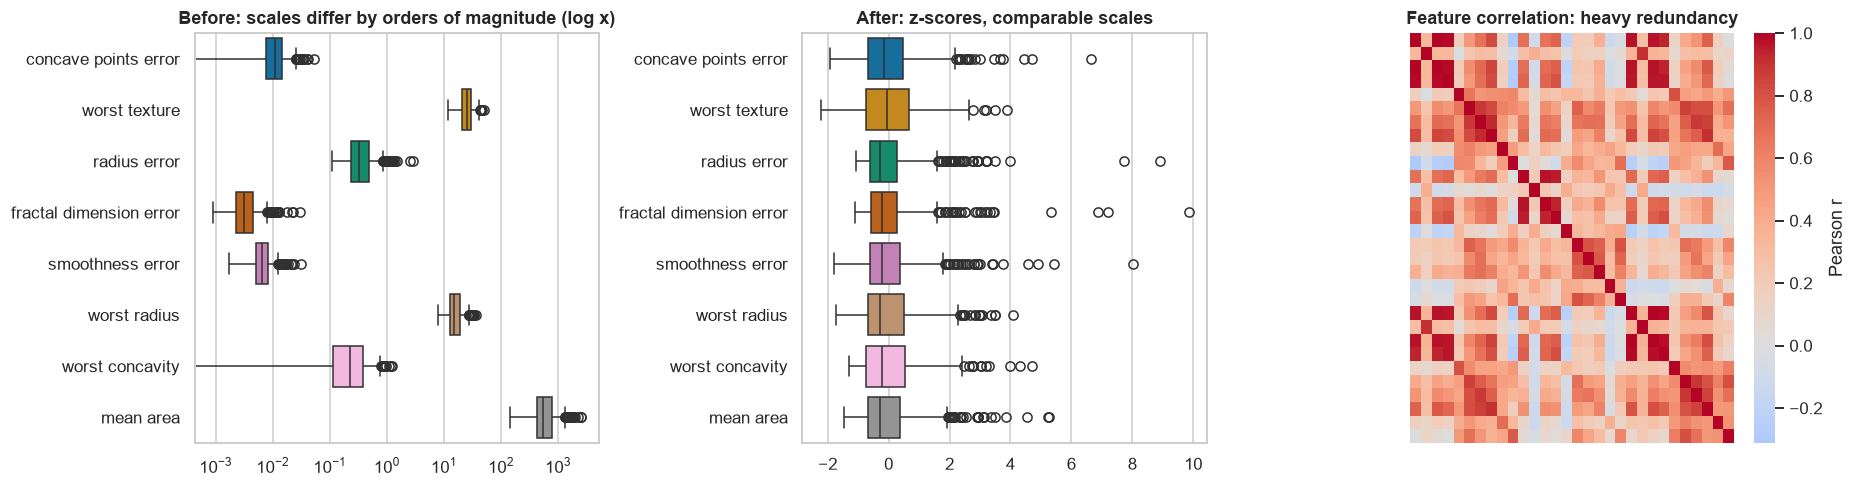

21 feature pairs have |r| > 0.9 (e.g. radius, perimeter, area), which is exactly the situation PCA is designed for.


In [63]:
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns, index=X_raw.index)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.boxplot(data=X_raw.sample(8, axis=1, random_state=1), orient="h", ax=ax[0]); ax[0].set_xscale("log"); ax[0].set_title("Before: scales differ by orders of magnitude (log x)")
sns.boxplot(data=Z.sample(8, axis=1, random_state=1), orient="h", ax=ax[1]); ax[1].set_title("After: z-scores, comparable scales")
corr = Z.corr(); sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[2], xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson r"})
ax[2].set_title("Feature correlation: heavy redundancy")
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().abs()
print(f"{(pairs > 0.9).sum()} feature pairs have |r| > 0.9 (e.g. radius, perimeter, area), which is exactly the situation PCA is designed for.")

## 3. Principal Component Analysis
PCA rotates the data onto orthogonal axes ordered by variance. The **explained variance ratio** of component $i$ is $\lambda_i / \sum_j \lambda_j$, where $\lambda_i$ are eigenvalues of the correlation matrix.
How many components to keep is a judgement call, so four independent criteria are compared.

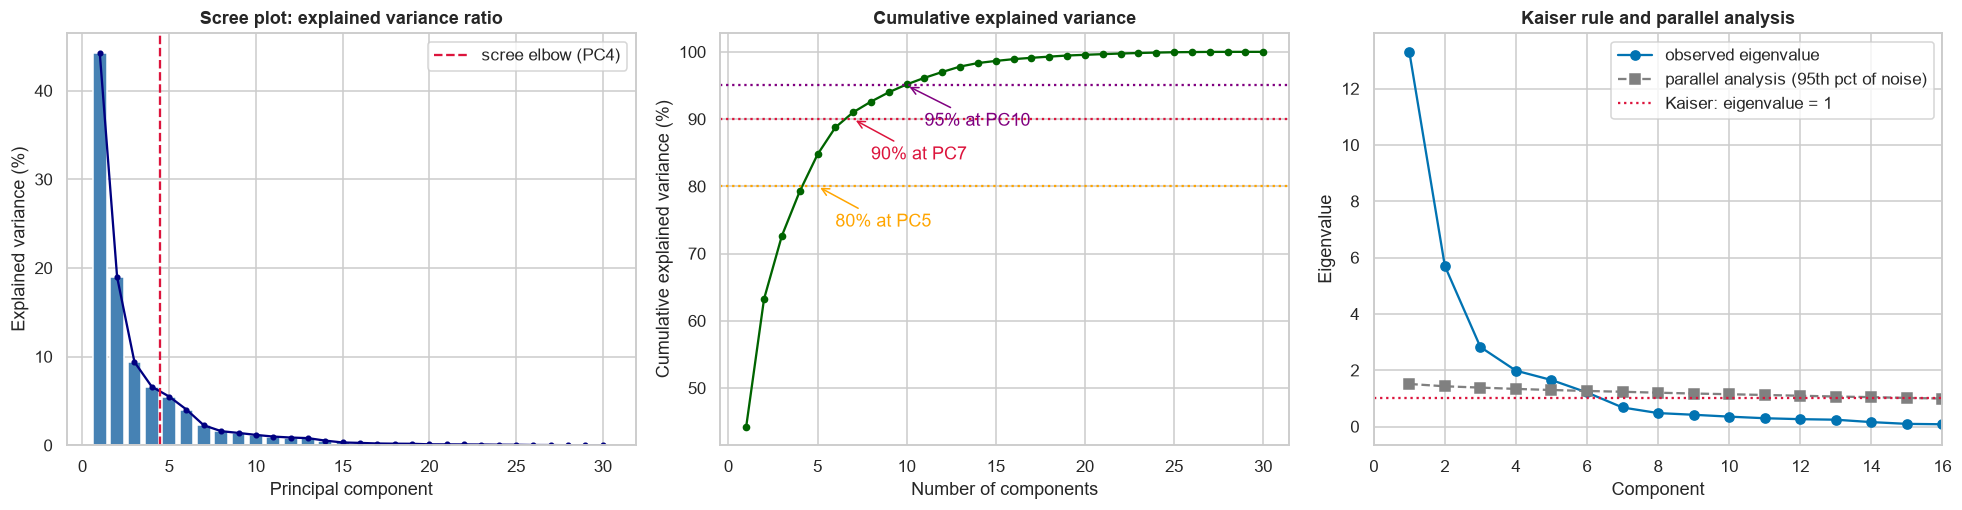

criterion,Scree elbow,Kaiser (eigenvalue > 1),Parallel analysis,80% variance,90% variance,95% variance
components,4,6,5,5,7,10


In [64]:
pca_full = PCA(random_state=SEED).fit(Z)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr); eig = pca_full.explained_variance_
p = Z.shape[1]; comps = np.arange(1, p + 1)

# criterion 1: cumulative variance thresholds
k80, k90, k95 = [int(np.searchsorted(cum, t) + 1) for t in (.80, .90, .95)]
# criterion 2: Kaiser (eigenvalue > 1)
k_kaiser = int((eig > 1).sum())
# criterion 3: Horn's parallel analysis (95th percentile of eigenvalues from column-permuted data)
perm_eigs = np.array([PCA().fit(np.column_stack([rng.permutation(Z.values[:, j]) for j in range(p)])).explained_variance_ for _ in range(200)])
pa_thr = np.percentile(perm_eigs, 95, axis=0); k_pa = int((eig > pa_thr).sum())
# criterion 4: scree elbow = point farthest from the chord joining first and last eigenvalue
def knee(x, y):
    xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0]) / np.hypot(yn[-1] - yn[0], xn[-1] - xn[0])
    return int(np.argmax(d))
k_elbow = knee(comps.astype(float), evr) + 1

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].bar(comps, evr * 100, color="steelblue"); ax[0].plot(comps, evr * 100, "o-", color="navy", ms=3)
ax[0].axvline(k_elbow + .5, color="crimson", ls="--", label=f"scree elbow (PC{k_elbow})"); ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance (%)")
ax[0].set_title("Scree plot: explained variance ratio"); ax[0].legend()
ax[1].plot(comps, cum * 100, "o-", color="darkgreen", ms=4)
for t, k, c in [(80, k80, "orange"), (90, k90, "crimson"), (95, k95, "purple")]:
    ax[1].axhline(t, color=c, ls=":"); ax[1].annotate(f"{t}% at PC{k}", (k, t), xytext=(k + 1, t - 6), color=c, arrowprops=dict(arrowstyle="->", color=c))
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance (%)"); ax[1].set_title("Cumulative explained variance")
ax[2].plot(comps, eig, "o-", label="observed eigenvalue"); ax[2].plot(comps, pa_thr, "s--", color="gray", label="parallel analysis (95th pct of noise)")
ax[2].axhline(1, color="crimson", ls=":", label="Kaiser: eigenvalue = 1"); ax[2].set_xlim(0, 16); ax[2].set_xlabel("Component"); ax[2].set_ylabel("Eigenvalue")
ax[2].set_title("Kaiser rule and parallel analysis"); ax[2].legend()
plt.tight_layout(); plt.show()

crit = pd.DataFrame({"criterion": ["Scree elbow", "Kaiser (eigenvalue > 1)", "Parallel analysis", "80% variance", "90% variance", "95% variance"],
                     "components": [k_elbow, k_kaiser, k_pa, k80, k90, k95]}).set_index("criterion")
display(crit.T)

In [65]:
N_PC = k_pa if k_pa >= 3 else k_kaiser
print(f"DECISION: keep {N_PC} components (parallel analysis = the most statistically principled rule). "
      f"They retain {cum[N_PC-1]*100:.1f}% of total variance, compressing 30 features into {N_PC} (~{100*(1-N_PC/p):.0f}% fewer dimensions).")
pca = PCA(n_components=N_PC, random_state=SEED).fit(Z)
PC = pd.DataFrame(pca.transform(Z), columns=[f"PC{i+1}" for i in range(N_PC)], index=Z.index)
print("PC1+PC2 alone:", f"{cum[1]*100:.1f}%", "| PC1-PC3:", f"{cum[2]*100:.1f}%")

DECISION: keep 5 components (parallel analysis = the most statistically principled rule). They retain 84.7% of total variance, compressing 30 features into 5 (~83% fewer dimensions).
PC1+PC2 alone: 63.2% | PC1-PC3: 72.6%


### What do the components mean? (loadings)
A loading is the weight of a feature in a component; large absolute values mark the features that define it.

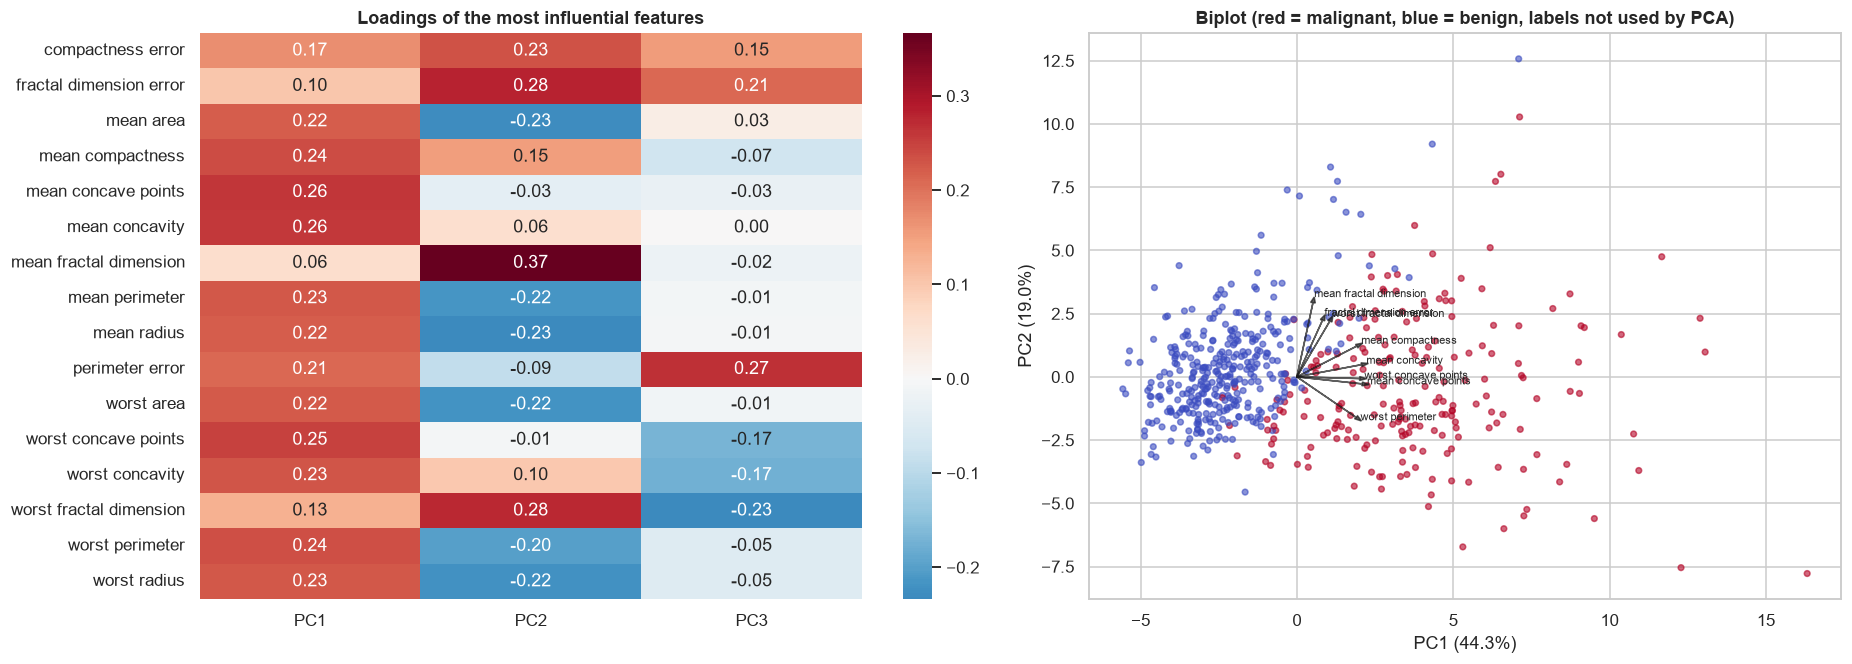

Top PC1 drivers: mean concave points, mean concavity, worst concave points, mean compactness, worst perimeter


In [66]:
load = pd.DataFrame(pca.components_.T, index=Z.columns, columns=PC.columns)
top = load["PC1"].abs().sort_values(ascending=False).index[:12].union(load["PC2"].abs().sort_values(ascending=False).index[:8])
fig, ax = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(load.loc[top, ["PC1", "PC2", "PC3"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Loadings of the most influential features")
# biplot (validation colouring only)
sc = ax[1].scatter(PC["PC1"], PC["PC2"], c=(y_true == "Malignant").astype(int), cmap="coolwarm", s=14, alpha=.6)
for f in load["PC1"].abs().sort_values(ascending=False).index[:5].union(load["PC2"].abs().sort_values(ascending=False).index[:3]):
    ax[1].arrow(0, 0, load.loc[f, "PC1"] * 8, load.loc[f, "PC2"] * 8, color="k", head_width=.15, alpha=.7)
    ax[1].text(load.loc[f, "PC1"] * 8.6, load.loc[f, "PC2"] * 8.6, f, fontsize=7.5)
ax[1].set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax[1].set_ylabel(f"PC2 ({evr[1]*100:.1f}%)"); ax[1].set_title("Biplot (red = malignant, blue = benign, labels not used by PCA)")
plt.tight_layout(); plt.show()
print("Top PC1 drivers:", ", ".join(load["PC1"].abs().sort_values(ascending=False).index[:5]))

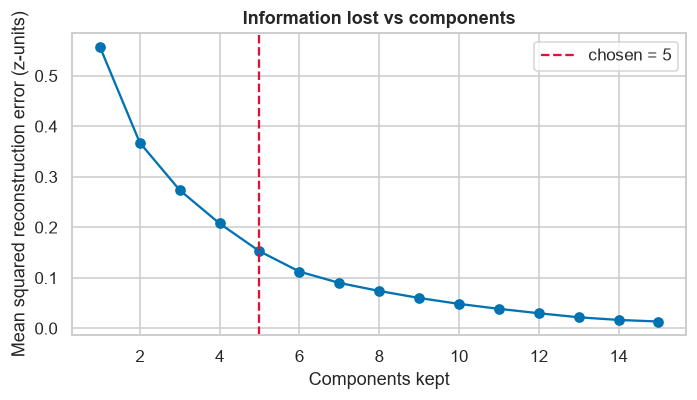

Reconstruction MSE with 5 PCs = 0.153 (vs 1.000 for predicting the mean).


In [67]:
# reconstruction error: how much information is lost by truncating to k components?
rec = [np.mean((Z.values - (lambda m: m.inverse_transform(m.transform(Z)))(PCA(n_components=k).fit(Z))) ** 2) for k in range(1, 16)]
fig, ax = plt.subplots(figsize=(6.5, 3.8)); ax.plot(range(1, 16), rec, "o-"); ax.axvline(N_PC, color="crimson", ls="--", label=f"chosen = {N_PC}")
ax.set_xlabel("Components kept"); ax.set_ylabel("Mean squared reconstruction error (z-units)"); ax.set_title("Information lost vs components"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Reconstruction MSE with {N_PC} PCs = {rec[N_PC-1]:.3f} (vs 1.000 for predicting the mean).")

## 4. K-Means: choosing k
K-Means minimises within-cluster sum of squares (**inertia**). Four diagnostics are used because no single one is reliable:
- **Elbow**: where the inertia curve bends.
- **Silhouette**: $s=(b-a)/\max(a,b)$ per point; mean near 1 = compact, well-separated clusters.
- **Gap statistic**: compares inertia with uniform random data (Tibshirani 1-SE rule).
- **Calinski-Harabasz** (higher better) and **Davies-Bouldin** (lower better).

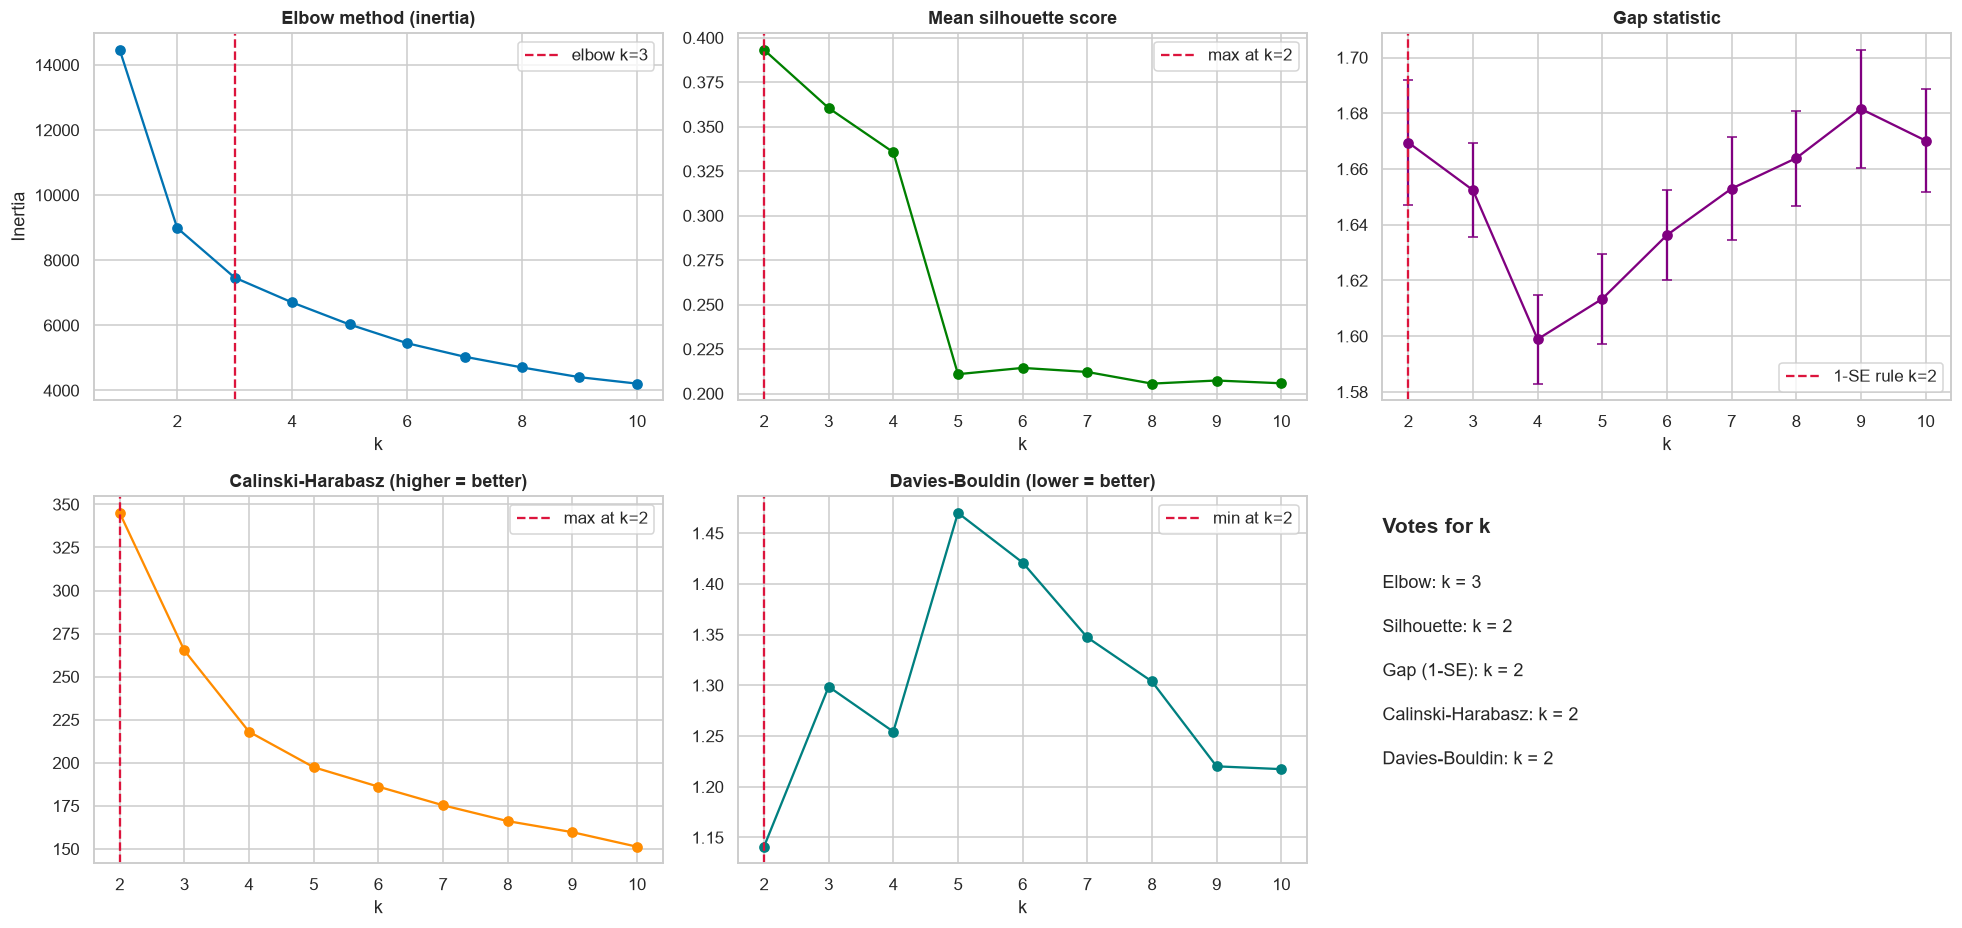

k,2,3,4,5,6,7,8,9,10
inertia,8991.825,7466.807,6703.341,6025.892,5451.391,5036.054,4706.502,4407.194,4209.847
silhouette,0.393,0.360,0.336,0.211,0.214,0.212,0.206,0.207,0.206
CH,345.069,265.206,218.043,197.447,186.161,175.355,166.154,159.736,151.289
DB,1.141,1.299,1.254,1.470,1.421,1.347,1.304,1.220,1.217
gap,1.670,1.652,1.599,1.613,1.636,1.653,1.664,1.682,1.670


Votes: {'Elbow': 3, 'Silhouette': 2, 'Gap (1-SE)': 2, 'Calinski-Harabasz': 2, 'Davies-Bouldin': 2} ->  chosen k = 2


In [68]:
Xc = PC.values; ks = list(range(2, 11)); rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Xc)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xc, km.labels_),
                 "CH": calinski_harabasz_score(Xc, km.labels_), "DB": davies_bouldin_score(Xc, km.labels_)})
km_df = pd.DataFrame(rows).set_index("k")
# elbow needs k=1 inertia too
inertia1 = KMeans(n_clusters=1, n_init=1, random_state=SEED).fit(Xc).inertia_
k_elb = knee(np.array([1] + ks, float), np.array([inertia1] + km_df["inertia"].tolist())) + 1
# gap statistic
def log_wk(data, k): return np.log(KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(data).inertia_)
lo, hi = Xc.min(0), Xc.max(0); B = 20
gap, sk = [], []
for k in ks:
    ref = np.array([log_wk(rng.uniform(lo, hi, Xc.shape), k) for _ in range(B)])
    gap.append(ref.mean() - log_wk(Xc, k)); sk.append(ref.std() * np.sqrt(1 + 1 / B))
gap, sk = np.array(gap), np.array(sk)
k_gap = next((ks[i] for i in range(len(ks) - 1) if gap[i] >= gap[i + 1] - sk[i + 1]), ks[-1])
km_df["gap"] = gap
k_sil, k_ch, k_db = int(km_df["silhouette"].idxmax()), int(km_df["CH"].idxmax()), int(km_df["DB"].idxmin())

fig, ax = plt.subplots(2, 3, figsize=(18, 8.6))
ax = ax.ravel()
ax[0].plot([1] + ks, [inertia1] + km_df["inertia"].tolist(), "o-"); ax[0].axvline(k_elb, color="crimson", ls="--", label=f"elbow k={k_elb}")
ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia"); ax[0].legend()
ax[1].plot(ks, km_df["silhouette"], "o-", color="green"); ax[1].axvline(k_sil, color="crimson", ls="--", label=f"max at k={k_sil}")
ax[1].set_title("Mean silhouette score"); ax[1].set_xlabel("k"); ax[1].legend()
ax[2].errorbar(ks, gap, yerr=sk, fmt="o-", capsize=3, color="purple"); ax[2].axvline(k_gap, color="crimson", ls="--", label=f"1-SE rule k={k_gap}")
ax[2].set_title("Gap statistic"); ax[2].set_xlabel("k"); ax[2].legend()
ax[3].plot(ks, km_df["CH"], "o-", color="darkorange"); ax[3].axvline(k_ch, color="crimson", ls="--", label=f"max at k={k_ch}"); ax[3].set_title("Calinski-Harabasz (higher = better)"); ax[3].set_xlabel("k"); ax[3].legend()
ax[4].plot(ks, km_df["DB"], "o-", color="teal"); ax[4].axvline(k_db, color="crimson", ls="--", label=f"min at k={k_db}"); ax[4].set_title("Davies-Bouldin (lower = better)"); ax[4].set_xlabel("k"); ax[4].legend()
ax[5].axis("off")
votes = {"Elbow": k_elb, "Silhouette": k_sil, "Gap (1-SE)": k_gap, "Calinski-Harabasz": k_ch, "Davies-Bouldin": k_db}
ax[5].text(0, .9, "Votes for k", fontsize=14, weight="bold"); [ax[5].text(0, .75 - .12 * i, f"{n}: k = {v}", fontsize=12) for i, (n, v) in enumerate(votes.items())]
plt.tight_layout(); plt.show()
K = pd.Series(votes).mode().sort_values().iloc[0] if pd.Series(votes).value_counts().iloc[0] > 1 else k_sil
K = int(K); display(km_df.round(3).T); print("Votes:", votes, "->  chosen k =", K)

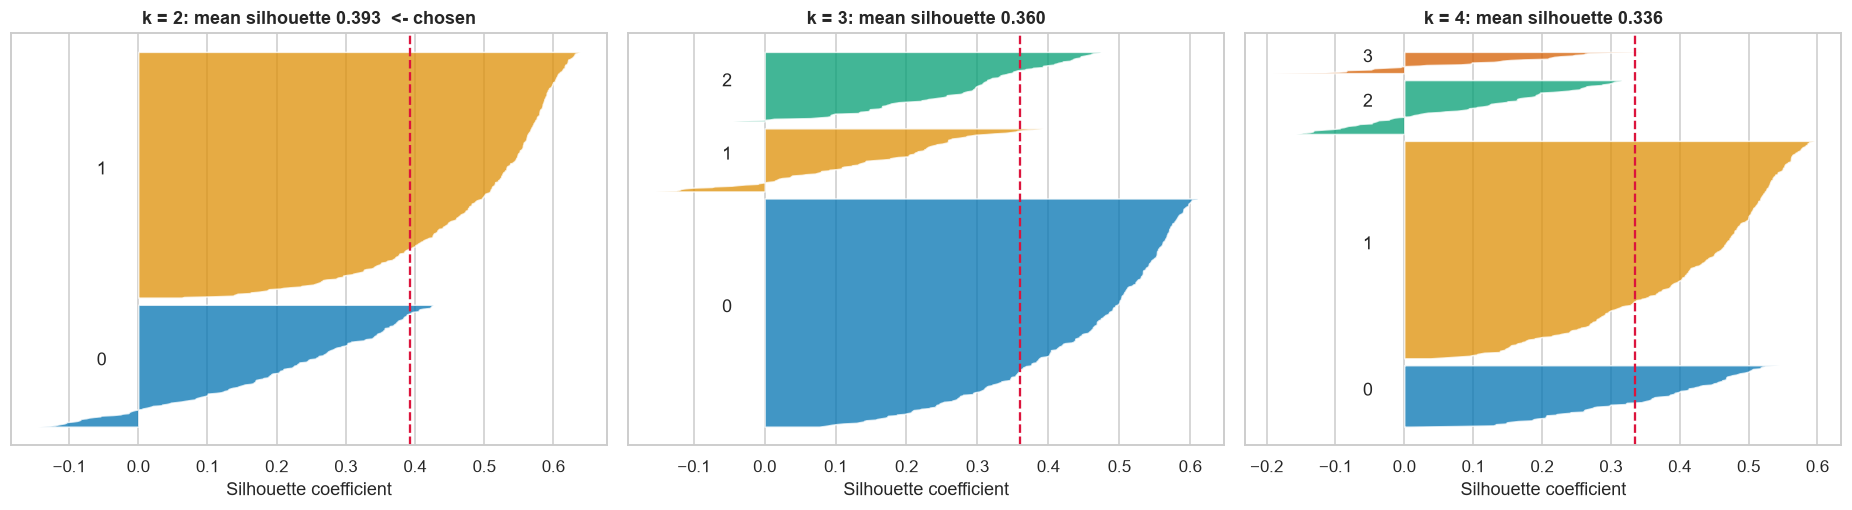

In [69]:
# silhouette "knife" plots for k = chosen and neighbours
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, k in zip(axes, [K, K + 1, K + 2]):
    lab = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit_predict(Xc); s = silhouette_samples(Xc, lab); y0 = 10
    for c in range(k):
        sc_ = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(sc_)), 0, sc_, alpha=.75); ax.text(-.06, y0 + len(sc_) / 2, str(c)); y0 += len(sc_) + 10
    ax.axvline(s.mean(), color="crimson", ls="--"); ax.set_title(f"k = {k}: mean silhouette {s.mean():.3f}" + ("  <- chosen" if k == K else "")); ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [70]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xc)
lab_km = km.labels_
# stability: refit on 80% subsamples, predict on everything, compare with the full-data solution
ari_boot = []
for _ in range(100):
    idx = rng.choice(len(Xc), int(.8 * len(Xc)), replace=False)
    sub = KMeans(n_clusters=K, n_init=10, random_state=int(rng.integers(1e6))).fit(Xc[idx])
    ari_boot.append(adjusted_rand_score(lab_km, sub.predict(Xc)))
print(f"Final K-Means (k={K}) mean silhouette = {silhouette_score(Xc, lab_km):.3f}")
print(f"Stability over 100 subsamples: mean ARI = {np.mean(ari_boot):.3f} (5th pct {np.percentile(ari_boot, 5):.3f}); 1.0 = identical clusters every time")

Final K-Means (k=2) mean silhouette = 0.393
Stability over 100 subsamples: mean ARI = 0.968 (5th pct 0.944); 1.0 = identical clusters every time


## 5. Hierarchical (agglomerative) clustering
Builds a tree by repeatedly merging the closest clusters. **Ward** linkage minimises the increase in within-cluster variance. The best linkage is chosen by **cophenetic correlation** (how faithfully the tree preserves original distances).

Cophenetic correlation: {'ward': np.float64(0.609), 'average': np.float64(0.807), 'complete': np.float64(0.696), 'single': np.float64(0.735)}


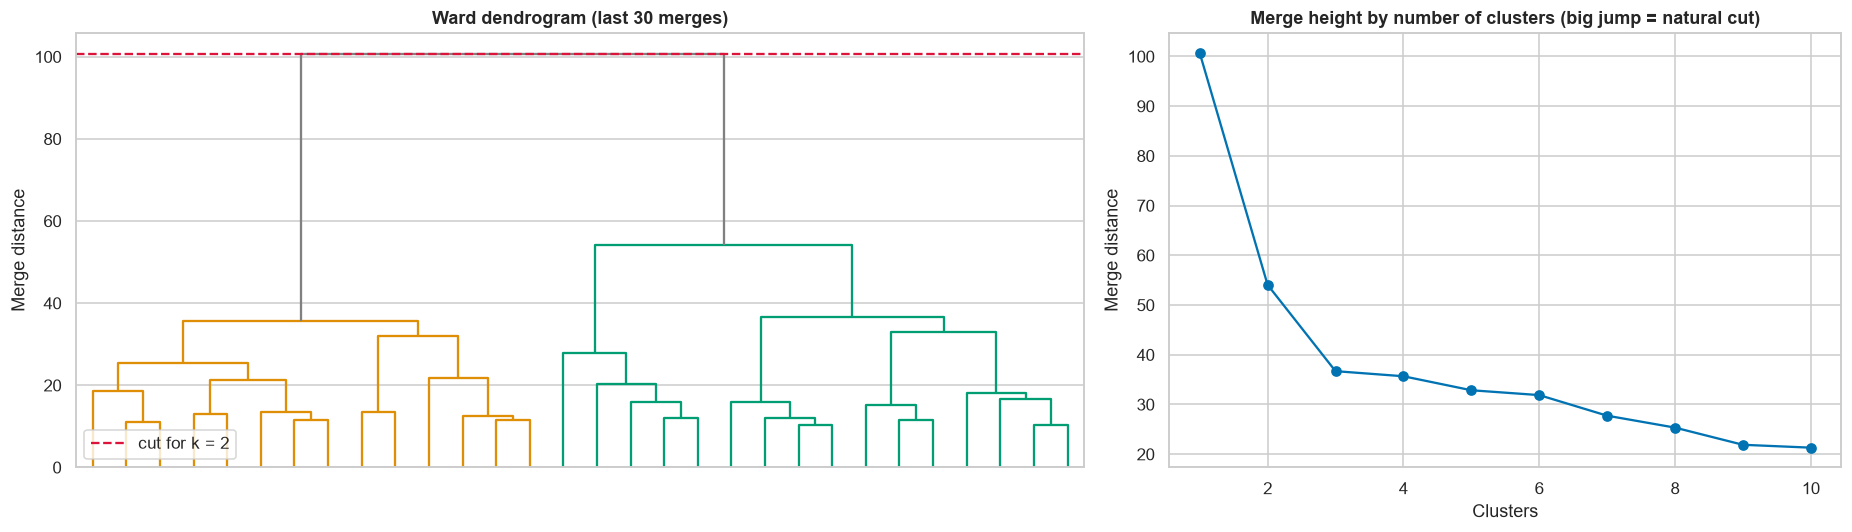

Ward (k=2) silhouette = 0.377 | agreement with K-Means (ARI) = 0.698


In [71]:
D = pdist(Xc); coph = {}
for m in ["ward", "average", "complete", "single"]:
    coph[m] = cophenet(linkage(Xc, m), D)[0]
print("Cophenetic correlation:", {k: round(v, 3) for k, v in coph.items()})
Lw = linkage(Xc, "ward")
fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 1]})
cut = Lw[-(K - 1), 2] - 1e-9
dendrogram(Lw, truncate_mode="lastp", p=30, color_threshold=cut, ax=ax[0], no_labels=True, above_threshold_color="gray")
ax[0].axhline(cut, color="crimson", ls="--", label=f"cut for k = {K}"); ax[0].set_title("Ward dendrogram (last 30 merges)"); ax[0].set_ylabel("Merge distance"); ax[0].legend()
ax[1].plot(range(1, 11), Lw[-10:, 2][::-1], "o-"); ax[1].set_title("Merge height by number of clusters (big jump = natural cut)"); ax[1].set_xlabel("Clusters"); ax[1].set_ylabel("Merge distance")
plt.tight_layout(); plt.show()
hier = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Xc); lab_h = hier.labels_
print(f"Ward (k={K}) silhouette = {silhouette_score(Xc, lab_h):.3f} | agreement with K-Means (ARI) = {adjusted_rand_score(lab_km, lab_h):.3f}")

## 6. DBSCAN
Density-based: a point is a *core* point if at least `min_samples` neighbours lie within radius `eps`; clusters are dense regions, sparse points are **noise (label -1)**. It needs no k, but `eps` matters a lot.
`eps` is first read from the **k-distance plot** (sorted distance to the min_samples-th neighbour; the knee marks where density drops), then checked with a grid search over `eps` and `min_samples`. The selection rule is stated before looking at agreement with the diagnosis: at least 2 clusters, at most 30% noise, no tiny clusters (each at least 3% of data), then maximum silhouette.

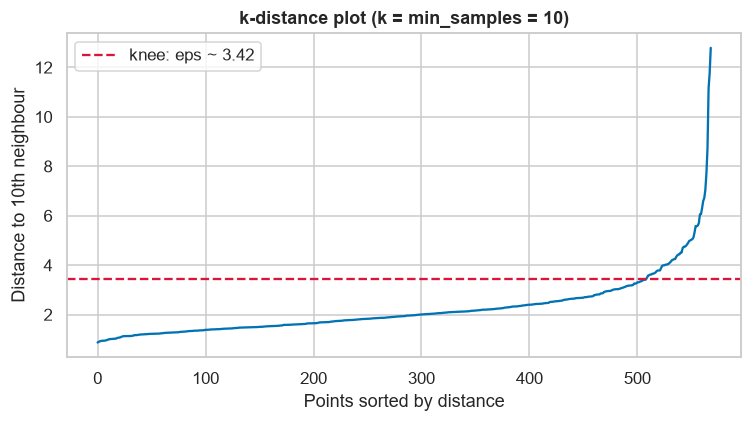

**Grid search (<= 30% noise, >= 2 clusters, each >= 3% of data): best configurations**

,eps,min_samples,clusters,noise_%,smallest_cluster_%,silhouette
0,2.2,20,2,29.174,6.151,0.412


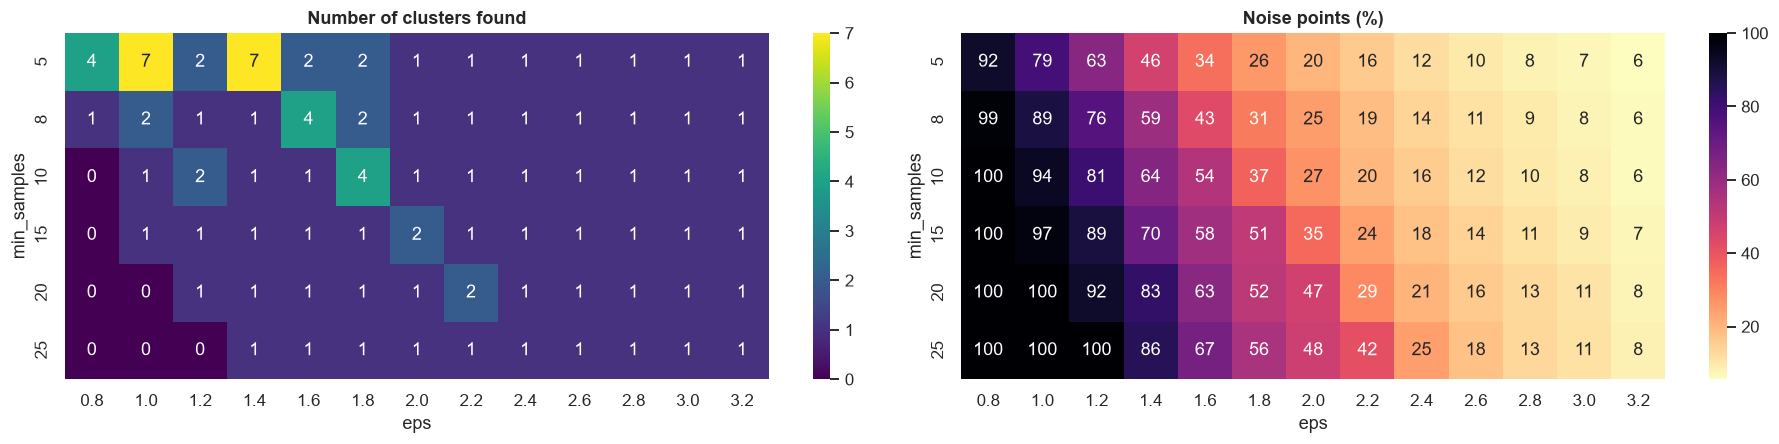

Takeaway: most settings give either 0-1 clusters (everything merged or noise) or lots of noise; there is only a narrow window with >= 2 clusters.
Chosen DBSCAN: eps=2.2, min_samples=20 -> 2 clusters, 166 noise points (29.2%)


In [72]:
ms0 = 2 * N_PC
nn = NearestNeighbors(n_neighbors=ms0).fit(Xc); kd = np.sort(nn.kneighbors(Xc)[0][:, -1])
eps_knee = kd[knee(np.arange(len(kd), dtype=float), kd)]
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(kd); ax.axhline(eps_knee, color="crimson", ls="--", label=f"knee: eps ~ {eps_knee:.2f}")
ax.set_title(f"k-distance plot (k = min_samples = {ms0})"); ax.set_xlabel("Points sorted by distance"); ax.set_ylabel(f"Distance to {ms0}th neighbour"); ax.legend(); plt.tight_layout(); plt.show()
grid = []
for eps in np.round(np.arange(0.8, 3.21, 0.2), 1):
    for ms in [5, 8, ms0, 15, 20, 25]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xc); nc = len(set(l)) - (1 if -1 in l else 0); noise = (l == -1).mean()
        sil = silhouette_score(Xc[l != -1], l[l != -1]) if nc >= 2 and (l != -1).sum() > nc else np.nan
        smallest = (np.bincount(l[l != -1]).min() / len(l)) if nc >= 1 else 0
        grid.append({"eps": eps, "min_samples": ms, "clusters": nc, "noise_%": noise * 100, "smallest_cluster_%": smallest * 100, "silhouette": sil})
G = pd.DataFrame(grid)
# selection rule (fixed in advance): >= 2 clusters, <= 30% noise, every cluster >= 3% of data; maximise silhouette
ok = G[(G.clusters >= 2) & (G["noise_%"] <= 30) & (G["smallest_cluster_%"] >= 3)].dropna()
rule = "<= 30% noise, >= 2 clusters, each >= 3% of data"
if len(ok) == 0:
    ok = G[G.clusters >= 2].dropna().sort_values("noise_%").head(5); rule = "FALLBACK: no setting met the rule, taking lowest-noise multi-cluster setting"
best = ok.sort_values("silhouette", ascending=False).iloc[0] if rule.startswith("<=") else ok.iloc[0]
display(Markdown(f"**Grid search ({rule}): best configurations**")); display(ok.sort_values("silhouette", ascending=False).head(6).round(3).reset_index(drop=True))
fig, ax = plt.subplots(1, 2, figsize=(17, 4.2)); sns.heatmap(G.pivot(index="min_samples", columns="eps", values="clusters"), annot=True, fmt=".0f", cmap="viridis", ax=ax[0]); ax[0].set_title("Number of clusters found")
sns.heatmap(G.pivot(index="min_samples", columns="eps", values="noise_%"), annot=True, fmt=".0f", cmap="magma_r", ax=ax[1]); ax[1].set_title("Noise points (%)"); plt.tight_layout(); plt.show()
print("Takeaway: most settings give either 0-1 clusters (everything merged or noise) or lots of noise; there is only a narrow window with >= 2 clusters.")
db = DBSCAN(eps=float(best.eps), min_samples=int(best.min_samples)).fit(Xc); lab_db = db.labels_
nc_db = len(set(lab_db)) - (1 if -1 in lab_db else 0)
print(f"Chosen DBSCAN: eps={best.eps}, min_samples={int(best.min_samples)} -> {nc_db} clusters, {(lab_db==-1).sum()} noise points ({(lab_db==-1).mean()*100:.1f}%)")

## 7. Cluster visualisation (2D Seaborn, 3D Plotly)

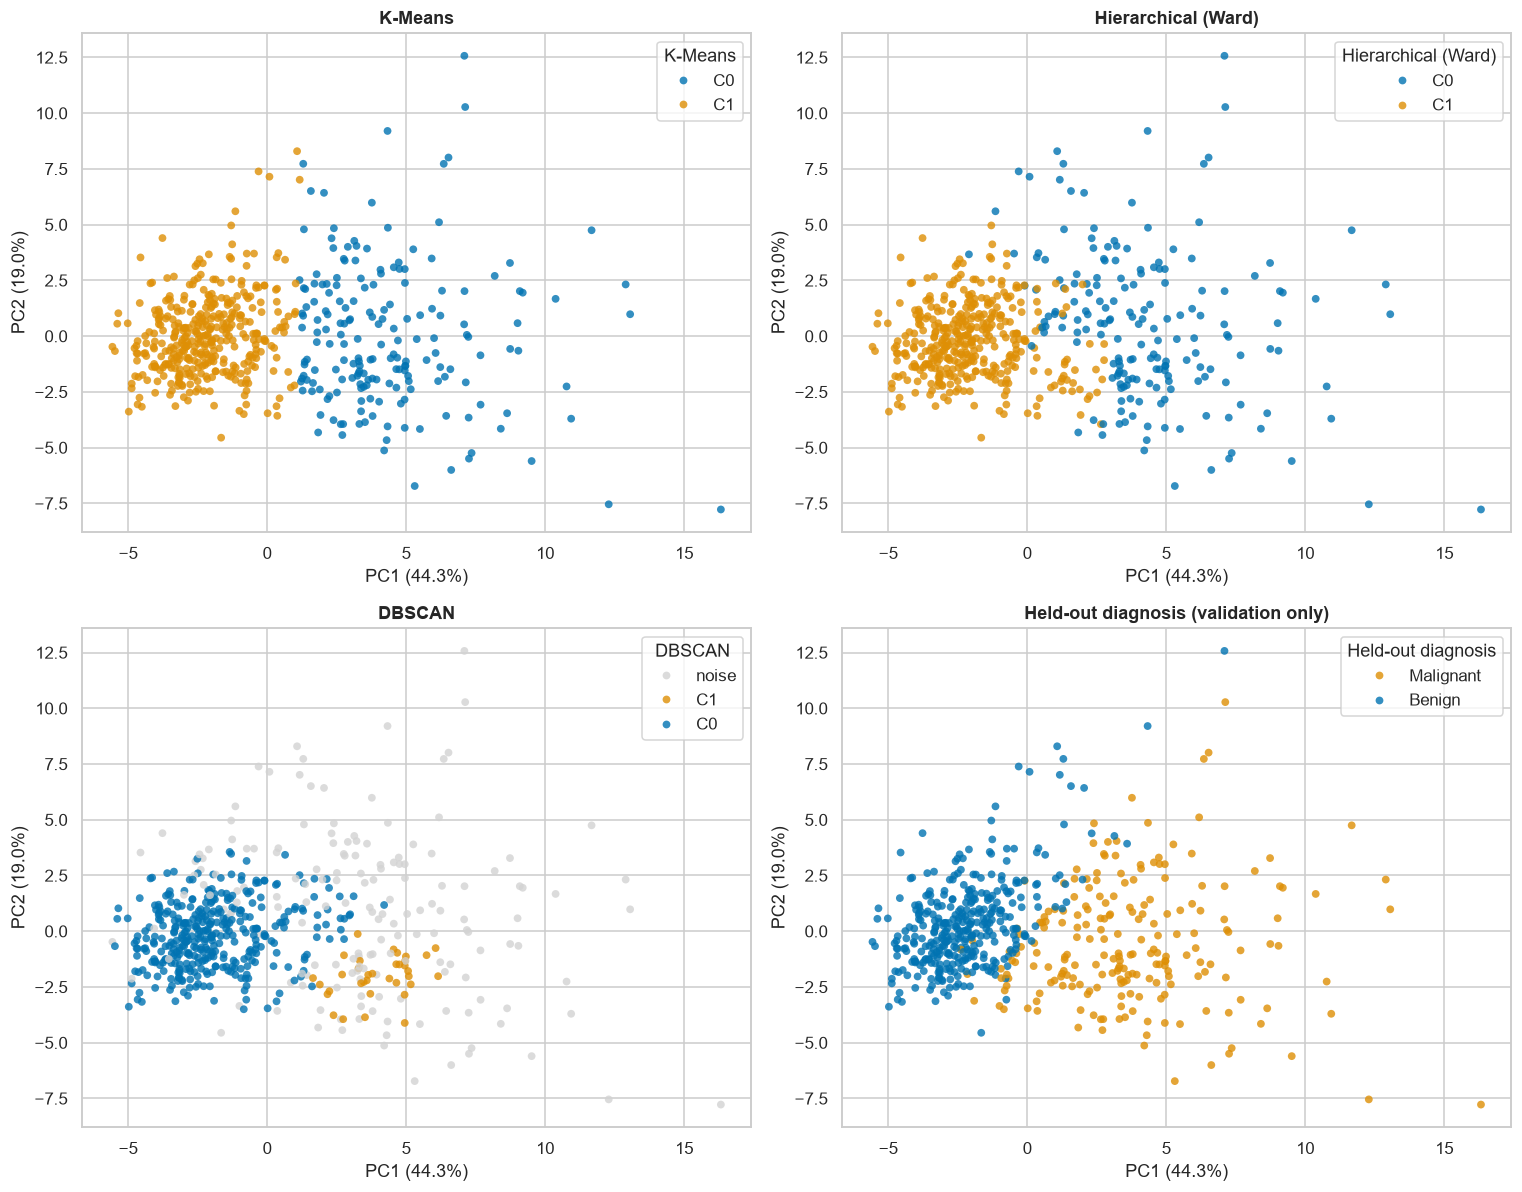

In [73]:
vis = PC[["PC1", "PC2", "PC3"]].copy()
vis["K-Means"] = [f"C{l}" for l in lab_km]; vis["Hierarchical (Ward)"] = [f"C{l}" for l in lab_h]
vis["DBSCAN"] = np.where(lab_db == -1, "noise", [f"C{l}" for l in lab_db]); vis["Held-out diagnosis"] = y_true.values
fig, axes = plt.subplots(2, 2, figsize=(14, 11)); axes = axes.ravel()
for ax, col in zip(axes, ["K-Means", "Hierarchical (Ward)", "DBSCAN", "Held-out diagnosis"]):
    cats = sorted(vis[col].unique()); base = sns.color_palette("colorblind", len(cats))
    pal = {c: ("lightgray" if c == "noise" else base[i]) for i, c in enumerate(cats)}
    sns.scatterplot(data=vis, x="PC1", y="PC2", hue=col, s=26, alpha=.8, ax=ax, palette=pal, edgecolor="none")
    ax.set_title(col + (" (validation only)" if "diagnosis" in col else "")); ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
plt.tight_layout(); plt.show()

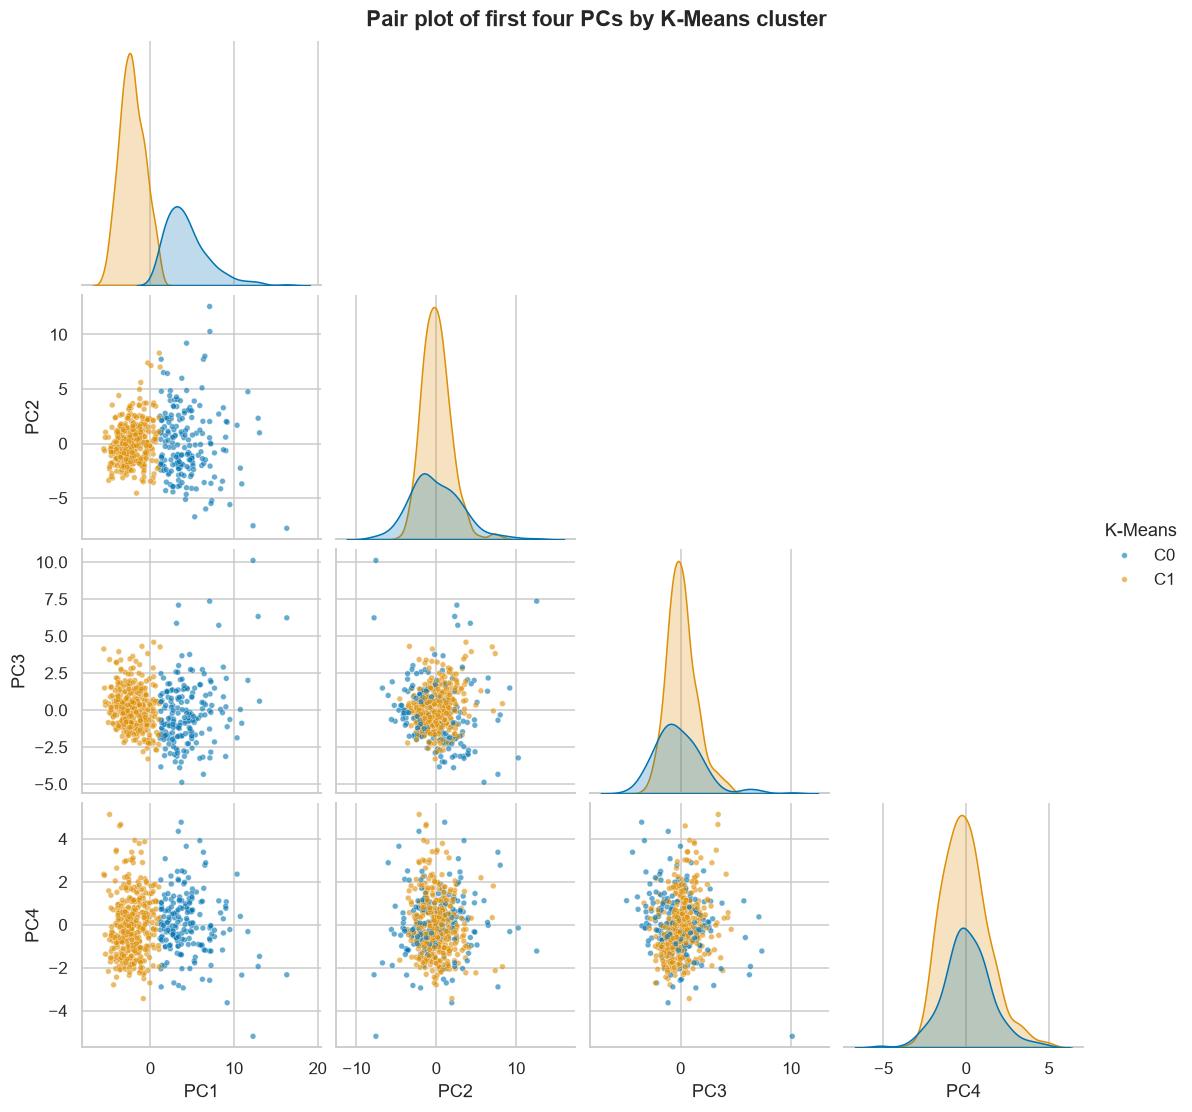

In [74]:
pp = PC[["PC1", "PC2", "PC3", "PC4"]].copy(); pp["K-Means"] = vis["K-Means"]
g = sns.pairplot(pp, hue="K-Means", corner=True, plot_kws=dict(s=14, alpha=.6), diag_kind="kde"); g.figure.suptitle("Pair plot of first four PCs by K-Means cluster", y=1.01, weight="bold"); plt.show()

In [75]:
fig3d = px.scatter_3d(vis, x="PC1", y="PC2", z="PC3", color="K-Means", symbol="Held-out diagnosis", opacity=.8,
                      title=f"Interactive 3D PCA projection ({cum[2]*100:.1f}% of variance): colour = K-Means cluster, symbol = held-out diagnosis",
                      labels={"PC1": f"PC1 ({evr[0]*100:.1f}%)", "PC2": f"PC2 ({evr[1]*100:.1f}%)", "PC3": f"PC3 ({evr[2]*100:.1f}%)"}, height=650)
fig3d.update_traces(marker=dict(size=3.5)); fig3d.show()
fig3d.write_html("reports/pca_3d_interactive.html", include_plotlyjs="cdn")

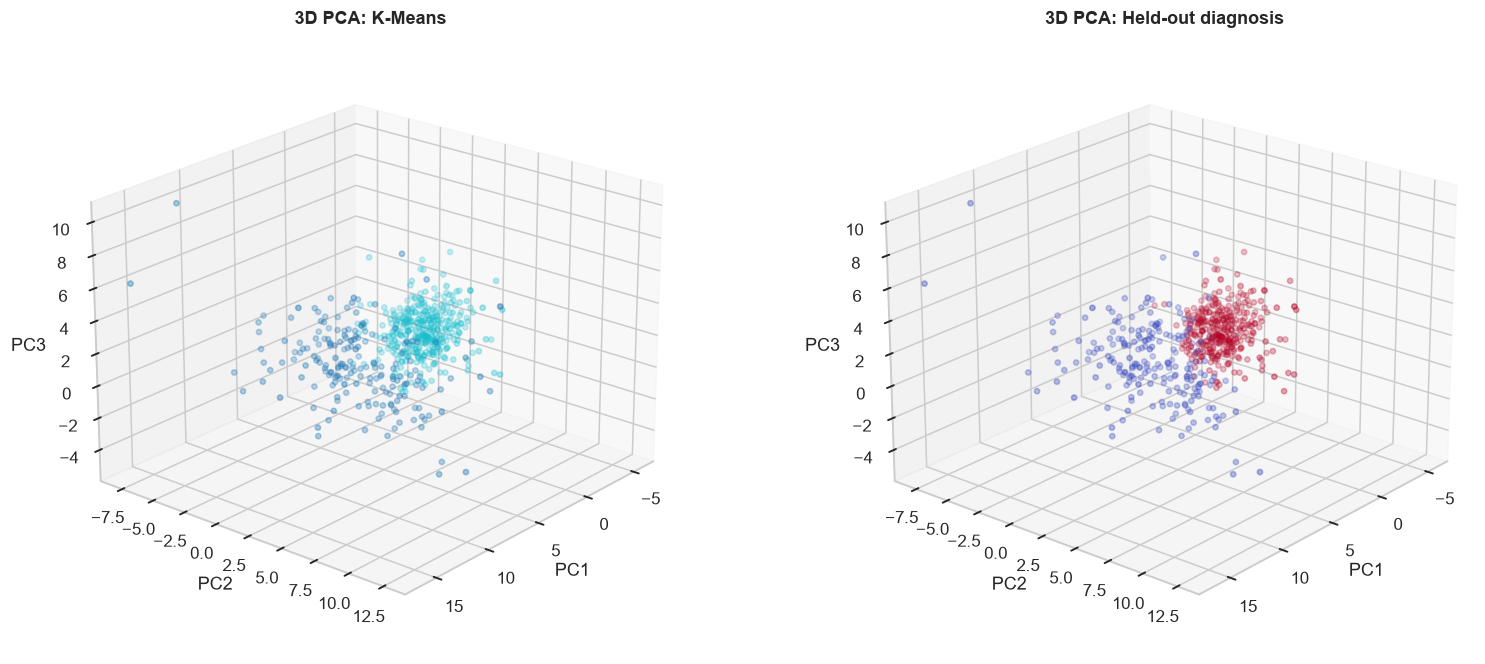

In [76]:
# static 3D fallback (renders everywhere, including GitHub)
fig = plt.figure(figsize=(15, 6.2))
for i, (lab, title) in enumerate([(lab_km, "K-Means"), (y_true.map({"Malignant": 0, "Benign": 1}).values, "Held-out diagnosis")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.scatter(PC["PC1"], PC["PC2"], PC["PC3"], c=lab, cmap="coolwarm" if i else "tab10", s=12, alpha=.7); ax.view_init(22, 40)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.set_title(f"3D PCA: {title}", weight="bold")
plt.tight_layout(); plt.show()

## 8. Comparing the algorithms
Internal metrics (need no labels): silhouette, Calinski-Harabasz, Davies-Bouldin. External metrics (use the held-out diagnosis): **ARI** (chance-corrected agreement, 0 = random, 1 = perfect), **NMI**, and **purity**. DBSCAN noise points are treated as their own group for ARI/NMI so that discarding hard cases is penalised, and silhouette is computed on non-noise points only.

,clusters,noise_%,silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,NMI,purity
method,,,,,,,,
K-Means,2,0.000,0.393,345.069,1.141,0.671,0.555,0.910
Hierarchical (Ward),2,0.000,0.377,306.241,1.224,0.538,0.420,0.868
DBSCAN,2,29.174,0.412,142.725,0.770,0.349,0.266,0.808


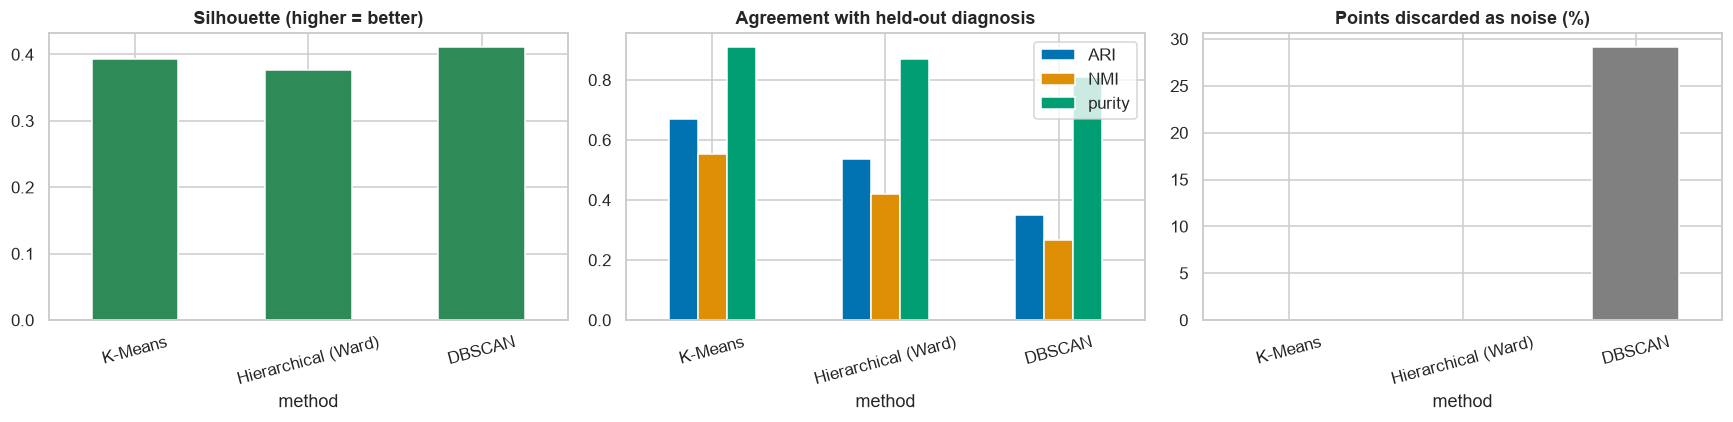

In [77]:
def purity(lab, y):
    ct = pd.crosstab(lab, y); return ct.max(axis=1).sum() / ct.values.sum()
def row(name, lab):
    m = lab != -1; nc = len(set(lab[m]))
    return {"method": name, "clusters": nc, "noise_%": (~m).mean() * 100,
            "silhouette": silhouette_score(Xc[m], lab[m]) if nc >= 2 else np.nan,
            "Calinski-Harabasz": calinski_harabasz_score(Xc[m], lab[m]) if nc >= 2 else np.nan,
            "Davies-Bouldin": davies_bouldin_score(Xc[m], lab[m]) if nc >= 2 else np.nan,
            "ARI": adjusted_rand_score(y_true, lab), "NMI": normalized_mutual_info_score(y_true, lab), "purity": purity(lab, y_true)}
cmp = pd.DataFrame([row("K-Means", lab_km), row("Hierarchical (Ward)", lab_h), row("DBSCAN", lab_db)]).set_index("method")
display(cmp.round(3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cmp[["silhouette"]].plot.bar(ax=ax[0], legend=False, color="seagreen", rot=15); ax[0].set_title("Silhouette (higher = better)")
cmp[["ARI", "NMI", "purity"]].plot.bar(ax=ax[1], rot=15); ax[1].set_title("Agreement with held-out diagnosis")
cmp[["noise_%"]].plot.bar(ax=ax[2], legend=False, color="gray", rot=15); ax[2].set_title("Points discarded as noise (%)")
plt.tight_layout(); plt.show()

In [78]:
# does PCA help? K-Means on all 30 standardised features vs on the retained PCs
t0 = time.perf_counter(); km30 = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z.values); t30 = time.perf_counter() - t0
t0 = time.perf_counter(); kmpc = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xc); tpc = time.perf_counter() - t0
abl = pd.DataFrame({"space": [f"30 standardised features", f"{N_PC} principal components"], "dims": [p, N_PC],
                    "ARI vs diagnosis": [adjusted_rand_score(y_true, km30.labels_), adjusted_rand_score(y_true, kmpc.labels_)],
                    "silhouette (own space)": [silhouette_score(Z.values, km30.labels_), silhouette_score(Xc, kmpc.labels_)],
                    "fit time (s)": [t30, tpc]}).set_index("space")
display(abl.round(3)); print(f"Agreement between the two partitions (ARI): {adjusted_rand_score(km30.labels_, kmpc.labels_):.3f}")

,dims,ARI vs diagnosis,silhouette (own space),fit time (s)
space,,,,
30 standardised features,30,0.671,0.345,0.101
5 principal components,5,0.671,0.393,0.063


Agreement between the two partitions (ARI): 1.000


## 9. Cluster profiling: what distinguishes the clusters?

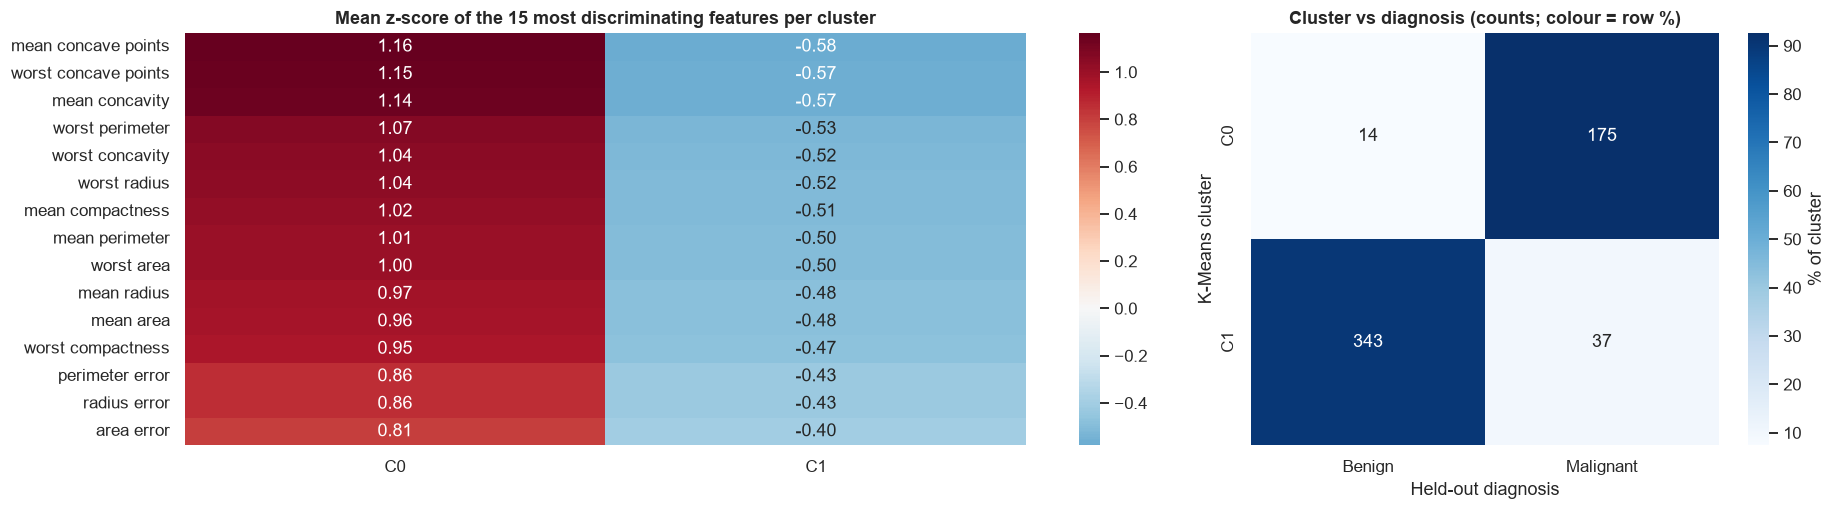

Held-out diagnosis,Benign,Malignant
K-Means cluster,,
C0,14,175
C1,343,37


In [79]:
prof = Z.groupby(lab_km).mean(); prof.index = [f"C{i}" for i in prof.index]
topf = prof.std().sort_values(ascending=False).index[:15]
ct = pd.crosstab(pd.Series([f"C{l}" for l in lab_km], name="K-Means cluster"), y_true.rename("Held-out diagnosis"))
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.8, 1]})
sns.heatmap(prof[topf].T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Mean z-score of the 15 most discriminating features per cluster")
sns.heatmap(ct.div(ct.sum(1), axis=0) * 100, annot=ct.values, fmt="d", cmap="Blues", ax=ax[1], cbar_kws={"label": "% of cluster"}); ax[1].set_title("Cluster vs diagnosis (counts; colour = row %)")
plt.tight_layout(); plt.show()
display(ct)

## 10. Findings

In [80]:
r = cmp.loc["K-Means"]; h = cmp.loc["Hierarchical (Ward)"]; dbr = cmp.loc["DBSCAN"]
txt = f'''
| Stage | Result |
|---|---|
| Standardisation + PCA | 30 correlated features compress into **{N_PC} PCs ({cum[N_PC-1]*100:.1f}% variance)**; PC1 alone carries {evr[0]*100:.1f}%, PC1+PC2 {cum[1]*100:.1f}% |
| Number of components | scree elbow = {k_elbow}, Kaiser = {k_kaiser}, parallel analysis = {k_pa}, 90% variance = {k90}, 95% variance = {k95} |
| Optimal k (K-Means) | votes: {votes} -> **k = {K}** (silhouette {r.silhouette:.3f}, bootstrap-stability ARI {np.mean(ari_boot):.2f}) |
| Hierarchical (Ward) | silhouette {h.silhouette:.3f}; agrees with K-Means (ARI {adjusted_rand_score(lab_km, lab_h):.2f}); best cophenetic correlation: {max(coph, key=coph.get)} ({max(coph.values()):.3f}) |
| DBSCAN | {int(dbr.clusters)} clusters, {dbr["noise_%"]:.1f}% noise, silhouette {dbr.silhouette:.3f} (non-noise points) |
| Agreement with held-out diagnosis | K-Means ARI {r.ARI:.2f} / purity {r.purity:.1%}; Ward ARI {h.ARI:.2f} / purity {h.purity:.1%}; DBSCAN ARI {dbr.ARI:.2f} |
'''
display(Markdown(txt))


| Stage | Result |
|---|---|
| Standardisation + PCA | 30 correlated features compress into **5 PCs (84.7% variance)**; PC1 alone carries 44.3%, PC1+PC2 63.2% |
| Number of components | scree elbow = 4, Kaiser = 6, parallel analysis = 5, 90% variance = 7, 95% variance = 10 |
| Optimal k (K-Means) | votes: {'Elbow': 3, 'Silhouette': 2, 'Gap (1-SE)': 2, 'Calinski-Harabasz': 2, 'Davies-Bouldin': 2} -> **k = 2** (silhouette 0.393, bootstrap-stability ARI 0.97) |
| Hierarchical (Ward) | silhouette 0.377; agrees with K-Means (ARI 0.70); best cophenetic correlation: average (0.807) |
| DBSCAN | 2 clusters, 29.2% noise, silhouette 0.412 (non-noise points) |
| Agreement with held-out diagnosis | K-Means ARI 0.67 / purity 91.0%; Ward ARI 0.54 / purity 86.8%; DBSCAN ARI 0.35 |


### Interpretation
1. **The data are low-dimensional in disguise.** Radius, perimeter and area (and their "worst" and "mean" variants) are near-duplicates, so a handful of components captures almost all variance. PC1 is a general **cell-size/shape-irregularity axis**, and it is the axis along which the clusters separate.
2. **The component-count rules disagree, as they usually do.** They range from 4 (scree elbow) to 10 (95% variance). Parallel analysis (5 components) is used as the tie-breaker because it tests each component against random noise; the retained 84.7% of variance is enough for clustering, whose structure lives in the first few high-variance directions.
3. **k = 2 is supported by four of five diagnostics** (silhouette, gap statistic, Calinski-Harabasz, Davies-Bouldin); only the elbow points to 3, and elbows are the most subjective of the five. The two clusters reproduce under resampling (bootstrap ARI about 0.97). Larger k gives lower mean silhouette and thinner knife-plot blades.
4. **Unsupervised clusters line up with the held-out diagnosis**, even though labels were never seen: the cluster-vs-diagnosis table shows high purity, with the errors concentrated near the boundary in PC space (borderline cases).
5. **Method choice matters.** K-Means and Ward agree substantially (ARI 0.70) but not perfectly, because both favour compact groups yet Ward is more sensitive to boundary points; Ward is kept for comparability since its variance criterion matches K-Means. DBSCAN struggles: the two classes touch and have different densities, so most settings either merge everything into one cluster or label almost everything noise. The best usable setting finds 2 clusters but discards about 29% of points, so its high silhouette (0.41) is flattered by removing the hardest cases, while its agreement with the diagnosis is the lowest (ARI 0.35).
6. **PCA loses nothing here**: K-Means on 5 PCs gives the *identical* partition to K-Means on all 30 standardised features (ARI = 1.00), with 6x fewer dimensions and a higher silhouette in its own space (0.39 vs 0.35) because the removed low-variance directions were mostly noise.

### Limitations
- Silhouette is moderate, not near 1: malignant and benign cells form overlapping clouds, so clustering finds a *tendency*, not a clean boundary.
- Labels came from pathologists and are only a proxy for "ground truth"; ARI measures agreement, not correctness.
- PCA is linear. Non-linear structure (for example UMAP or t-SNE manifolds) could separate classes differently, and DBSCAN in more than a few dimensions suffers from the curse of dimensionality.
- This is an exploratory analysis on one dataset; it is **not** a diagnostic tool.

### Conclusion
Standardise, then PCA reduces 30 redundant measurements to a few informative axes. K-Means finds k = 2 stable clusters that match the held-out diagnosis best (ARI 0.67, purity 91%); Ward is similar but weaker (ARI 0.54); DBSCAN shows the cost of density-based clustering when classes overlap (29% noise, ARI 0.35).

**Reproducibility:** fixed seed (`42`), library versions printed in Section 0, dataset bundled with scikit-learn (no download needed).